In [4]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

In [5]:
#define state

class BMIState(TypedDict):

  weight_kg: float
  height_m: float
  bmi: float

  category: str

In [6]:
def calculate_bmi(state: BMIState): 
  height = state['height_m']
  weight = state['weight_kg']

  bmi = weight/(height**2)

  state['bmi'] = round(bmi, 2)
  return state


In [15]:
def define_category(state:  BMIState) -> BMIState:
  weight = state['weight_kg']

  if weight >= 90:
    state['category'] = 'overweight'
  
  return state

In [18]:
#define your graph

graph = StateGraph(BMIState)

#add nodes to your graph
graph.add_node('calculate_bmi', calculate_bmi)
graph.add_node('define_category', define_category)

#add your edges
graph.add_edge(START, 'calculate_bmi')
graph.add_edge('calculate_bmi', 'define_category')
graph.add_edge('define_category', END)

workflow = graph.compile()

In [19]:
#execute the graph

initial_state = {'weight_kg':91, 'height_m':1.73}

final_state = workflow.invoke(initial_state)

print(final_state)

{'weight_kg': 91, 'height_m': 1.73, 'bmi': 30.41, 'category': 'overweight'}


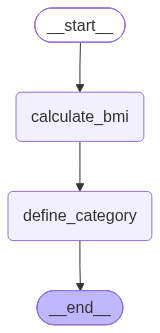

In [10]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())